# Search4Cure.AI: executable walkthrough

Run the cells in order. This notebook calls the project functions to query **real arXiv data**, download one version, extract text by physical PDF page, and create traceable text chunks. Running it again makes new source requests and creates new local retrieval/extraction records.

Use the **Search4Cure (.venv)** kernel after the notebook setup in the README. Saved outputs are snapshots of a particular execution, not evidence that the latest source results are unchanged.

Start Docker Desktop before running the database cells. They create a local password file, start PostgreSQL, and check the connection. No `.env` in `data/` is needed.

The document-storage cell imports real download metadata into PostgreSQL and shows the SQL row as a pandas DataFrame.

The raster-image cell saves PNG derivatives with page/position provenance and shows one reduced preview. It does not identify complete scientific figures.

The full-page cell renders every physical page and links its actual PNG to the text and chunk IDs from that same page. Embedded-image extraction remains a separate, available step.

The page-context storage cell imports page text, PNG references and processing states into PostgreSQL and checks a repeated import.

In [1]:
import json
import logging
import os
from pathlib import Path
import ssl
import subprocess
import sys
import time

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "arxiv_search.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "arxiv_search.py").is_file():
    raise RuntimeError("Open the notebook from the Search4Cure project directory.")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Use an existing system trust store only when this macOS Python lacks a default CA file.
if sys.platform == "darwin" and ssl.get_default_verify_paths().cafile is None:
    system_ca = Path("/etc/ssl/cert.pem")
    if system_ca.is_file():
        os.environ["SSL_CERT_FILE"] = str(system_ca)
        print("Using the system CA bundle; HTTPS verification remains enabled.")

logging.basicConfig(level=logging.INFO, format="%(message)s", stream=sys.stdout, force=True)

import pymupdf
from arxiv_search import search_one
from download_pdf import download_pdf
from extract_text import extract_text
from chunk_text import chunk_text

QUERY = "all:diabetes"
# The working directory is the project root, including when opened from notebooks/.
OUTPUT_DIR = Path("data/arxiv")
print(f"Python {sys.version.split()[0]}; PyMuPDF {pymupdf.VersionBind}")
print(f"Search query: {QUERY}")
from database import HEALTH_SQL, PASSWORD_FILE, create_password_file, check_connection

from database import initialize_schema
from store_document import DOCUMENT_SQL, store_document, read_document

from extract_images import extract_images

from render_pages import render_pages

from store_pages import store_pages, read_page_contexts


Using the system CA bundle; HTTPS verification remains enabled.
Python 3.13.12; PyMuPDF 1.28.2
Search query: all:diabetes


## 1. Query publication metadata

This cell contacts the arXiv API for at most one result. Keep first-submission time, version-submission time, and our retrieval time distinct. Unknown fields remain unknown.

In [2]:
print("Querying arXiv...")
search_result = search_one(QUERY)
if search_result["document"] is None:
    raise RuntimeError("No publication matched this query.")
print(json.dumps(search_result, indent=2, ensure_ascii=False))

Querying arXiv...


{
  "query": "all:diabetes",
  "request_url": "https://export.arxiv.org/api/query?search_query=all%3Adiabetes&start=0&max_results=1&sortBy=submittedDate&sortOrder=descending",
  "retrieved_at": "2026-11-04T23:49:46.452863+00:00",
  "document": {
    "arxiv_id": "2611.04405",
    "version": 1,
    "title": "DR-LiteNet: A Lightweight Explainable Hybrid CNN Framework for Imbalanced Diabetic Retinopathy Grading via Adaptive SMOTE Fusion",
    "source_url": "http://arxiv.org/abs/2611.04405v1",
    "first_submitted_at": "2026-11-03T06:44:25Z",
    "version_submitted_at": "2026-11-03T06:44:25Z"
  }
}


## 2. Download the exact version

The download requires a known version, streams bytes to disk, and records a SHA-256 fingerprint and a separate PDF retrieval time. The pause respects the API request spacing. Only one importer should run at a time.

In [3]:
print("Waiting 3.1 seconds before the PDF request...")
time.sleep(3.1)
download_result = download_pdf(search_result, OUTPUT_DIR)
print(json.dumps(download_result, indent=2, ensure_ascii=False))

Waiting 3.1 seconds before the PDF request...


PDF saved: data/arxiv/2611.04405v1/932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075.pdf (577377 bytes)


Metadata saved: data/arxiv/2611.04405v1/f3a0b71beb28415dae904937f74d306a.json


{
  "search": {
    "query": "all:diabetes",
    "request_url": "https://export.arxiv.org/api/query?search_query=all%3Adiabetes&start=0&max_results=1&sortBy=submittedDate&sortOrder=descending",
    "retrieved_at": "2026-11-04T23:49:46.452863+00:00",
    "document": {
      "arxiv_id": "2611.04405",
      "version": 1,
      "title": "DR-LiteNet: A Lightweight Explainable Hybrid CNN Framework for Imbalanced Diabetic Retinopathy Grading via Adaptive SMOTE Fusion",
      "source_url": "http://arxiv.org/abs/2611.04405v1",
      "first_submitted_at": "2026-11-03T06:44:25Z",
      "version_submitted_at": "2026-11-03T06:44:25Z"
    }
  },
  "pdf_url": "https://arxiv.org/pdf/2611.04405v1",
  "pdf_retrieved_at": "2026-11-04T23:49:49.762168+00:00",
  "sha256": "932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075",
  "size_bytes": 577377,
  "local_path": "data/arxiv/2611.04405v1/932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075.pdf",
  "status": "downloaded",
  "metada

## 3. Extract text by physical PDF page

The extractor verifies the saved PDF hash before parsing it. It records the parser version/configuration, page numbers starting at 1, empty pages, and any NUL replacements. Each attempt creates its own JSON result; a failed attempt does not replace the source or a previous result.

In [4]:
extraction_result = extract_text(download_result["metadata_path"])
assert extraction_result["download"]["sha256"] == download_result["sha256"]
assert extraction_result["page_count"] == len(extraction_result["pages"])
summary = {
    "arxiv_id": extraction_result["download"]["search"]["document"]["arxiv_id"],
    "version": extraction_result["download"]["search"]["document"]["version"],
    "status": extraction_result["status"],
    "page_count": extraction_result["page_count"],
    "empty_pages": extraction_result["empty_pages"],
    "total_characters": extraction_result["total_characters"],
    "parser": extraction_result["parser"],
    "parser_repaired_pdf": extraction_result["parser_repaired_pdf"],
    "output": extraction_result["metadata_path"],
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

Verifying PDF hash: data/arxiv/2611.04405v1/932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075.pdf


Page 1/6: 6714 characters


Page 2/6: 7058 characters


Page 3/6: 4269 characters


Page 4/6: 7055 characters


Page 5/6: 6945 characters


Page 6/6: 5573 characters


Extraction record saved: data/arxiv/2611.04405v1/extracted/a7c138409f2a4ffe987fa7116114ad69.json


{
  "arxiv_id": "2611.04405",
  "version": 1,
  "status": "extracted",
  "page_count": 6,
  "empty_pages": [],
  "total_characters": 37614,
  "parser": {
    "name": "PyMuPDF",
    "version": "1.28.2",
    "text_mode": "text",
    "sort": true,
    "ocr": false,
    "page_numbering": "physical PDF pages, starting at 1",
    "nul_handling": "replace NUL with U+FFFD and record the replacement count"
  },
  "parser_repaired_pdf": false,
  "output": "data/arxiv/2611.04405v1/extracted/a7c138409f2a4ffe987fa7116114ad69.json"
}


## 4. Split page text into traceable chunks

A word window keeps up to `MAX_WORDS` non-whitespace runs, with `OVERLAP_WORDS` repeated between adjacent windows. Chunks never cross page boundaries. Character offsets preserve the exact source slice. The chosen word count is a demonstration configuration, not a validated model-token budget or retrieval-quality optimum.

Chunk IDs include document version, PDF hash, parser/chunking configuration, page, and content. Equivalent reruns retain IDs even when retrieval records have new timestamps or filenames.

In [5]:
MAX_WORDS = 100
OVERLAP_WORDS = 20
chunk_result = chunk_text(extraction_result["metadata_path"],
                          max_words=MAX_WORDS, overlap_words=OVERLAP_WORDS)
print(json.dumps({
    "status": chunk_result["status"],
    "chunk_count": chunk_result["chunk_count"],
    "pages_without_text": chunk_result["pages_without_text"],
    "configuration": chunk_result["chunking"],
    "output": chunk_result["metadata_path"],
}, indent=2, ensure_ascii=False))

example = chunk_result["chunks"][0]
source_page = extraction_result["pages"][example["page_number"] - 1]
assert example["text"] == source_page["text"][example["start_char"]:example["end_char"]]
print("First chunk; its exact source-page slice was checked:")
print(json.dumps(example, indent=2, ensure_ascii=False))

Page 1/6: 8 chunks


Page 2/6: 10 chunks


Page 3/6: 6 chunks


Page 4/6: 10 chunks


Page 5/6: 8 chunks


Page 6/6: 8 chunks


Chunk record saved: data/arxiv/2611.04405v1/chunks/717879fe88ef482894cff9654ba8fb83.json


{
  "status": "chunked",
  "chunk_count": 50,
  "pages_without_text": [],
  "configuration": {
    "method": "page_word_windows_v1",
    "max_words": 100,
    "overlap_words": 20,
    "word_definition": "non-whitespace runs",
    "offsets": "Unicode character indices, end-exclusive",
    "cross_page": false
  },
  "output": "data/arxiv/2611.04405v1/chunks/717879fe88ef482894cff9654ba8fb83.json"
}
First chunk; its exact source-page slice was checked:
{
  "chunk_id": "9ae7df4122b58fb74a4d284eda91437e338bdf6008cfccb74223b578ebb5c871",
  "arxiv_id": "2611.04405",
  "version": 1,
  "source_pdf_sha256": "932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075",
  "page_number": 1,
  "chunk_number": 1,
  "start_char": 4,
  "end_char": 1363,
  "text": "DR-LiteNet: A Lightweight Explainable Hybrid CNN Framework for\n    Imbalanced Diabetic Retinopathy Grading via Adaptive SMOTE Fusion\n\n\n                                Nishi Kanta Paul    Md Shihabul Islam Shovo\n                     

## 5. Inspect one page

Change `PAGE_NUMBER` and rerun only this cell to inspect a different page. These are physical PDF pages, which may differ from printed page labels. A nonempty extraction does not by itself prove correct reading order or scientific relevance.

In [6]:
PAGE_NUMBER = 1
page = extraction_result["pages"][PAGE_NUMBER - 1]
document = extraction_result["download"]["search"]["document"]
print(f"Source: {document['arxiv_id']}v{document['version']}, physical page {page['page_number']}")
print(f"Source URL: {document['source_url']}")
print(f"PDF SHA-256: {extraction_result['download']['sha256']}")
print(f"Page status: {page['status']}; NUL replacements: {page['nul_replacements']}")
print("\nText preview (first 500 characters):\n")
print(page["text"][:500])

Source: 2611.04405v1, physical page 1
Source URL: http://arxiv.org/abs/2611.04405v1
PDF SHA-256: 932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075
Page status: extracted; NUL replacements: 0

Text preview (first 500 characters):

    DR-LiteNet: A Lightweight Explainable Hybrid CNN Framework for
    Imbalanced Diabetic Retinopathy Grading via Adaptive SMOTE Fusion


                                Nishi Kanta Paul    Md Shihabul Islam Shovo
                                 NIMISHES Lab               NIMISHES Lab

                                        Dhaka, Bangladesh                Dhaka, Bangladesh

                                    nishikantapaul108@gmail.com        shihabul900@gmail.com

                         


## 6. Prepare local PostgreSQL

The next cell creates `data/postgres/password.txt` only if it does not exist. It prints the path and status, never the password. The file is excluded from Git. No `.env` file is required.

Docker Compose starts a separate local PostgreSQL container and enables pgvector on first initialization. The first start may download the image. The database port is bound to `127.0.0.1` only. An existing password file is preserved; changing it does not update a password already stored in the database volume.

In [7]:
created = create_password_file()
print(f"Password file: {PASSWORD_FILE}")
print("Created; contents hidden." if created else "Already exists; kept unchanged; contents hidden.")
command = ["docker", "compose", "up", "-d", "--wait", "--wait-timeout", "60", "postgres"]
print("Running:", " ".join(command), flush=True)
with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
    exit_code = process.wait()
print(f"Docker process exit code: {exit_code}")
if exit_code != 0:
    raise RuntimeError("PostgreSQL startup failed. Check Docker Desktop and the output above.")

Password file: data/postgres/password.txt
Already exists; kept unchanged; contents hidden.
Running: docker compose up -d --wait --wait-timeout 60 postgres


 Container search4cure-local-postgres-1  Running


 Container search4cure-local-postgres-1  Waiting


 Container search4cure-local-postgres-1  Healthy


Docker process exit code: 0


## 7. Check the actual database

This read-only SQL query reports the connected database, PostgreSQL and pgvector versions, and the number of public tables. It does not import documents or create application tables. Connection and statement waits are limited to five seconds each. Credentials are not included in the result.

In [8]:
print("Read-only connection query:")
print(HEALTH_SQL.strip())
print(json.dumps(check_connection(), indent=2))

Read-only connection query:
SELECT current_database() AS database,
       current_user AS db_user,
       current_setting('server_version') AS postgres_version,
       (SELECT extversion FROM pg_extension WHERE extname = 'vector') AS pgvector_version,
       (SELECT count(*) FROM pg_tables WHERE schemaname = 'public') AS public_table_count,
       1 AS check_value;
Connecting to local PostgreSQL at 127.0.0.1:55432


{
  "database": "search4cure",
  "db_user": "search4cure",
  "postgres_version": "16.15 (Debian 16.15-1.pgdg12+2)",
  "pgvector_version": "0.8.7",
  "public_table_count": 2,
  "check_value": 1
}


## 8. Store one document version and display its SQL metadata

Create the document table explicitly, then import the real download record from this run. Each `(arxiv_id, version)` can occur only once. The importer verifies the PDF fingerprint and size. Importing the same version and content again returns `unchanged`; a changed hash raises a conflict and preserves the stored row.

The SQL row keeps the first imported download snapshot. Later retrieval attempts remain in local JSON files. Source submission times are not exact public-availability times; unknown times stay `NULL`. The database storage time describes our own write.

A pandas DataFrame displays the SQL result in Python memory. This does not store page text, chunks or vectors in SQL. The download status does not assert successful parsing.

In [9]:
import pandas as pd

initialize_schema()
print("Document table initialized.")
started = time.perf_counter()
first_import = store_document(download_result["metadata_path"])
first_seconds = time.perf_counter() - started
started = time.perf_counter()
second_import = store_document(download_result["metadata_path"])
second_seconds = time.perf_counter() - started
print(f"Import durations (single local observation): {first_seconds:.6f}s; repeat {second_seconds:.6f}s")
print("First import in this run:", json.dumps(first_import))
print("Repeated import:", json.dumps(second_import))
assert second_import["status"] == "unchanged"
row = read_document(first_import["arxiv_id"], first_import["version"])
assert row["sha256"] == download_result["sha256"]
print("Parameterized SQL (values are passed separately):")
print(DOCUMENT_SQL.strip())
documents_df = pd.DataFrame([row])
print("Rows returned for this document version:", len(documents_df))
assert len(documents_df) == 1
print(documents_df[["arxiv_id", "version", "status", "size_bytes"]].to_string(index=False))
display(documents_df[["arxiv_id", "version", "title", "status", "pdf_retrieved_at", "stored_at"]])

Connecting to local PostgreSQL at 127.0.0.1:55432


Document table initialized.
Connecting to local PostgreSQL at 127.0.0.1:55432


Document metadata unchanged: 2611.04405v1


Connecting to local PostgreSQL at 127.0.0.1:55432


Document metadata unchanged: 2611.04405v1


Import durations (single local observation): 0.016067s; repeat 0.015578s
First import in this run: {"status": "unchanged", "arxiv_id": "2611.04405", "version": 1, "sha256": "932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075"}
Repeated import: {"status": "unchanged", "arxiv_id": "2611.04405", "version": 1, "sha256": "932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075"}
Connecting to local PostgreSQL at 127.0.0.1:55432


Parameterized SQL (values are passed separately):
SELECT arxiv_id, version, title, source_url, pdf_url, first_submitted_at,
       version_submitted_at, metadata_retrieved_at, pdf_retrieved_at,
       sha256, size_bytes, local_path, metadata_path, status, stored_at
FROM document_versions
WHERE arxiv_id = %s AND version = %s;
Rows returned for this document version: 1
  arxiv_id  version     status  size_bytes
2611.04405        1 downloaded      577377


,arxiv_id,version,title,status,pdf_retrieved_at,stored_at
0,2611.04405,1,DR-LiteNet: A Lightweight Explainable Hybrid C...,downloaded,2026-11-04 16:36:49.980198+00:00,2026-11-04 16:36:51.570138+00:00


## 9. Extract referenced raster images

This cell verifies the PDF hash, finds raster-image occurrences on each physical page, and saves PNG derivatives. A reused image has one content-addressed PNG and separate occurrence records for its pages and positions. Soft transparency masks are applied; non-gray/non-RGB color spaces are converted to RGB.

`extracted` means all reported raster occurrences were saved. `no_images` means none were reported; vector drawings and text can still be present. `partial` means at least one occurrence failed or lacks an extractable PDF object reference. Those failures remain in the attempt JSON. Inline/unresolved images have no fallback rendering.

Bounding boxes use unrotated PyMuPDF page coordinates in points. Rotation, clipping, overlays and captions are not reconstructed into complete figures. The source PDF remains unchanged. PNG files and attempt records stay local; image SQL storage and CLIP embeddings are later steps.

Verifying PDF hash for image extraction: data/arxiv/2611.04405v1/932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075.pdf


Page 1/6: 0 raster occurrences; 0 extracted


Page 2/6: 0 raster occurrences; 0 extracted


Page 3/6: 1 raster occurrences; 1 extracted


Page 4/6: 0 raster occurrences; 0 extracted


Page 5/6: 0 raster occurrences; 0 extracted


... (2 outputs left out)

{
  "status": "extracted",
  "page_count": 6,
  "extracted_count": 1,
  "unique_asset_count": 1,
  "failed_count": 0,
  "unsupported_count": 0,
  "metadata_path": "data/arxiv/2611.04405v1/images/2ed98f019f6f4ee5bda5717fbeea2533.json"
}
 page_number  image_number  xref    status  width  height error
           3             1   323 extracted   2031     865  None


,page_number,image_number,xref,status,width,height,error
0,3,1,323,extracted,2031,865,None


Preview source: 2611.04405v1, physical page 3, image 1
Source-page bounding box: [54.0, 53.99639892578125, 541.2724609375, 261.5250244140625]
Saved PNG: data/arxiv/2611.04405v1/images/assets/8dfefe9a865277b558960f4492e3be0b5aca33b58278dd953634441925224223.png


Reduced preview: 508 x 217; stored image: 2031 x 865

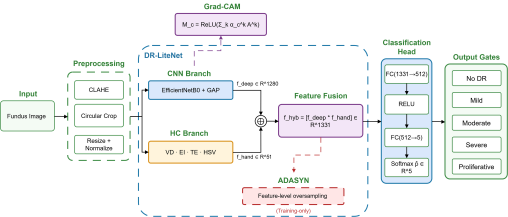

In [10]:
from IPython.display import Image, display

image_result = extract_images(download_result["metadata_path"])
print(json.dumps({key: image_result[key] for key in (
    "status", "page_count", "extracted_count", "unique_asset_count",
    "failed_count", "unsupported_count", "metadata_path",
)}, indent=2))
image_rows = [{key: item.get(key) for key in (
    "page_number", "image_number", "xref", "status", "width", "height", "error",
)} for item in image_result["images"]]
if image_rows:
    images_df = pd.DataFrame(image_rows)
    print(images_df.to_string(index=False))
    display(images_df)
else:
    print("No referenced raster images were reported; this is not evidence of a figure-free PDF.")

successful_images = [item for item in image_result["images"] if item["status"] == "extracted"]
if successful_images:
    example = successful_images[0]
    print(f"Preview source: {example['arxiv_id']}v{example['version']}, physical page {example['page_number']}, image {example['image_number']}")
    print("Source-page bounding box:", example["bbox"])
    print("Saved PNG:", example["local_path"])
    preview = pymupdf.Pixmap(example["local_path"])
    while max(preview.width, preview.height) > 800:
        preview.shrink(1)
    print(f"Reduced preview: {preview.width} x {preview.height}; stored image: {example['width']} x {example['height']}")
    display(Image(data=preview.tobytes("png")))
if image_result["status"] == "partial":
    print("PARTIAL extraction: inspect the failed/unsupported rows and the saved attempt JSON.")

## 10. Preserve complete page context

Render every physical page, including pages without embedded raster images or extractable text. Each page has its own JSON record linking a full-page PNG, exact extracted page text, chunk IDs, document version and PDF hash. Input extraction/chunk snapshots must match this PDF and each other; chunk text must match the associated page slice.

The default is 144 DPI, RGB, white background, with annotations and PDF rotation respected. A full page means its complete visible PDF CropBox, as in a PDF viewer. Hidden content outside that box is not included. Rendering processes one page at a time and applies a configurable per-page pixel limit.

Page IDs identify the logical PDF page; render IDs additionally identify the rendering configuration. Successful PNGs are not rewritten on equivalent reruns. New JSON files represent new processing attempts. The renderer writes local records; the later page-context cell imports them into SQL. Search and model calls are not implemented yet.

This follows the text-plus-page-image design principle described in the [official OpenAI file-input documentation](https://developers.openai.com/api/docs/guides/file-inputs). The later answer step must load the selected pages' actual image bytes and associated text into a vision-capable model; a filename alone is not visual evidence.

Text extraction and image rendering have independent error handling. A text failure leaves `text=None` and records `text_error`, while `image_status="rendered"` identifies a usable PNG. The attempt is `partial` and the CLI returns a nonzero status until the text failure is resolved. An empty text string remains a successful, empty extraction.

Verifying PDF hash for full-page rendering: data/arxiv/2611.04405v1/932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075.pdf


Full page 1/6: rendered; text=extracted; linked chunks=8


Full page 2/6: rendered; text=extracted; linked chunks=10


Full page 3/6: rendered; text=extracted; linked chunks=6


Full page 4/6: rendered; text=extracted; linked chunks=10


Full page 5/6: rendered; text=extracted; linked chunks=8


... (2 outputs left out)

{
  "status": "rendered",
  "page_count": 6,
  "rendered_count": 6,
  "failed_count": 0,
  "text_failed_count": 0,
  "image_failed_count": 0,
  "metadata_path": "data/arxiv/2611.04405v1/pages/fbb88d12a64c452a8a29950060f3d4f4.json"
}
 page   status text_status image_status  width  height  text_characters  linked_chunks error
    1 rendered   extracted     rendered   1191    1684             6714              8  None
    2 rendered   extracted     rendered   1191    1684             7058             10  None
    3 rendered   extracted     rendered   1191    1684             4269              6  None
    4 rendered   extracted     rendered   1191    1684             7055             10  None
    5 rendered   extracted     rendered   1191    1684             6945              8  None
    6 rendered   extracted     rendered   1191    1684             5573              8  None


,page,status,text_status,image_status,width,height,text_characters,linked_chunks,error
0,1,rendered,extracted,rendered,1191,1684,6714,8,None
1,2,rendered,extracted,rendered,1191,1684,7058,10,None
2,3,rendered,extracted,rendered,1191,1684,4269,6,None
3,4,rendered,extracted,rendered,1191,1684,7055,10,None
4,5,rendered,extracted,rendered,1191,1684,6945,8,None
5,6,rendered,extracted,rendered,1191,1684,5573,8,None


Source: 2611.04405v1, physical PDF page 3
Page record: data/arxiv/2611.04405v1/pages/records/fbcefad831c148b3a78a1ae7dc982fc7.json
PDF SHA-256: 932ec59803c4c1495ebfbb7dd3b58e17afdbbc24e459e5a48f35f48a54bd3075
Associated page text (first 400 characters):
Figure 1: DR-LiteNet architecture. The CNN branch (EfficientNetB0 + GAP) yields 1,280-d deep features; the HC branch
yields 51-d lesion descriptors – vessel density (VD), exudate intensity (EI), texture entropy (TE), HSV colour histogram (CH)
– concatenated into a 1,331-d hybrid vector fhyb. ADASYN oversampling applies during training only; Grad CAM maps
derive from EfficientNetB0’s last convoluti


Actual full-page PNG: data/arxiv/2611.04405v1/pages/assets/d39cec3d70cdb43fb2f61b92cece1b70dfb64bfb325211fddf4025fb26bac02e.png
Reduced notebook preview: 596 x 842


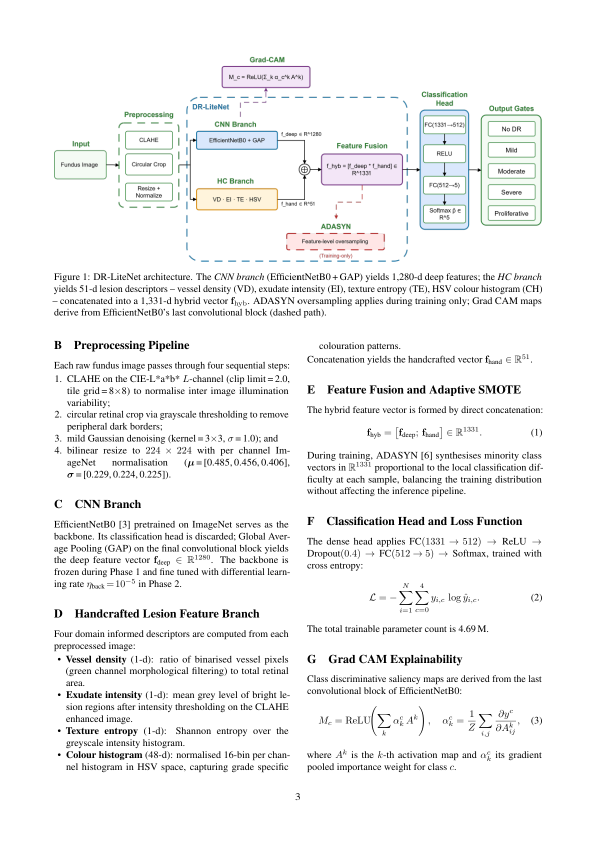

In [11]:
import hashlib

page_result = render_pages(
    download_result["metadata_path"],
    extraction_path=extraction_result["metadata_path"],
    chunks_path=chunk_result["metadata_path"],
    dpi=144,
)
print(json.dumps({key: page_result[key] for key in (
    "status", "page_count", "rendered_count", "failed_count",
    "text_failed_count", "image_failed_count", "metadata_path",
)}, indent=2))
page_rows = [{
    "page": item["page_number"], "status": item["status"],
    "text_status": item["text_status"], "image_status": item["image_status"],
    "width": item["image"]["width"] if item["image"] else None,
    "height": item["image"]["height"] if item["image"] else None,
    "text_characters": len(item["text"]) if item["text"] is not None else None,
    "linked_chunks": len(item["chunk_ids"]), "error": item["error"],
} for item in page_result["pages"]]
pages_df = pd.DataFrame(page_rows)
print(pages_df.to_string(index=False))
display(pages_df)

PAGE_TO_SHOW = min(3, page_result["page_count"])
selected_page = next(item for item in page_result["pages"] if item["page_number"] == PAGE_TO_SHOW)
assert selected_page["text"] == extraction_result["pages"][PAGE_TO_SHOW - 1]["text"]
assert selected_page["chunk_ids"] == [c["chunk_id"] for c in chunk_result["chunks"] if c["page_number"] == PAGE_TO_SHOW]
print(f"Source: {selected_page['arxiv_id']}v{selected_page['version']}, physical PDF page {PAGE_TO_SHOW}")
print("Page record:", selected_page.get("record_path"))
print("PDF SHA-256:", selected_page["source_pdf_sha256"])
print("Associated page text (first 400 characters):")
print(selected_page["text"][:400])
if selected_page["image"] is not None:
    png_path = Path(selected_page["image"]["local_path"])
    assert hashlib.sha256(png_path.read_bytes()).hexdigest() == selected_page["image"]["sha256"]
    print("Actual full-page PNG:", png_path)
    preview = pymupdf.Pixmap(str(png_path))
    while max(preview.width, preview.height) > 1000:
        preview.shrink(1)
    print(f"Reduced notebook preview: {preview.width} x {preview.height}")
    display(Image(data=preview.tobytes("png")))
if page_result["status"] != "rendered":
    print("INCOMPLETE page rendering: inspect failed page records before using them as evidence.")

## 10a. Synthetic example: keep the image after a text error

This offline example generates a small temporary PDF and deliberately makes `get_text()` raise an exception. It is a simulated failure, not an observed problem with the arXiv publication. No synthetic record is imported into SQL. The example verifies that the actual PNG exists, the failed text remains unknown, and a retry recovers text without rewriting the existing PNG.

In [12]:
import tempfile
from unittest.mock import patch

with tempfile.TemporaryDirectory(prefix="search4cure-synthetic-") as directory:
    demo_root = Path(directory)
    demo_pdf = demo_root / "SYNTHETIC.pdf"
    with pymupdf.open() as pdf:
        page = pdf.new_page(width=160, height=200)
        page.insert_text((15, 30), "SYNTHETIC text-error demo", fontsize=8)
        pdf.save(demo_pdf)
    demo_metadata = demo_root / "SYNTHETIC-download.json"
    demo_metadata.write_text(json.dumps({
        "status": "downloaded", "local_path": str(demo_pdf),
        "sha256": hashlib.sha256(demo_pdf.read_bytes()).hexdigest(),
        "search": {"query": "SYNTHETIC TEST ONLY", "document": {
            "arxiv_id": "2401.00001", "version": 1, "title": "SYNTHETIC fixture",
        }},
    }))
    with patch("render_pages.pymupdf.Page.get_text",
               side_effect=RuntimeError("SYNTHETIC text extraction failure")):
        demo_failed = render_pages(demo_metadata, dpi=72)
    demo_page = demo_failed["pages"][0]
    demo_png = Path(demo_page["image"]["local_path"])
    assert demo_page["text"] is None
    assert demo_page["text_status"] == "failed"
    assert demo_page["image_status"] == "rendered" and demo_png.is_file()
    print("SYNTHETIC failure result:")
    print(json.dumps({
        "attempt_status": demo_failed["status"], "text": demo_page["text"],
        "text_error": demo_page["text_error"], "image_status": demo_page["image_status"],
        "PNG_exists": demo_png.is_file(),
    }, indent=2))
    saved_mtime = demo_png.stat().st_mtime_ns
    demo_retry = render_pages(demo_metadata, dpi=72)
    assert demo_retry["status"] == "rendered"
    assert demo_retry["pages"][0]["text_status"] == "extracted"
    assert demo_png.stat().st_mtime_ns == saved_mtime
    print("Retry: text recovered; existing PNG kept unchanged.")

Verifying PDF hash for full-page rendering: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-bk503xgg/SYNTHETIC.pdf


Page 1 text extraction failed: RuntimeError: SYNTHETIC text extraction failure


Full page 1/1: rendered; text=failed; linked chunks=0


Full-page attempt record saved: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-bk503xgg/pages/1223050c6cfa403ea214fb20267b52a5.json


SYNTHETIC failure result:
{
  "attempt_status": "partial",
  "text": null,
  "text_error": "RuntimeError: SYNTHETIC text extraction failure",
  "image_status": "rendered",
  "PNG_exists": true
}
Verifying PDF hash for full-page rendering: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-bk503xgg/SYNTHETIC.pdf


Full page 1/1: rendered; text=extracted; linked chunks=0


Full-page attempt record saved: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-bk503xgg/pages/ffc4c1b24b57481c83ff07055c977010.json


Retry: text recovered; existing PNG kept unchanged.


## 11. Store page contexts in PostgreSQL

Each page is linked by document version and exact PDF hash to its parent in `document_versions`. The importer validates text/PNG fingerprints, identities and image dimensions. PNG bytes remain on disk; SQL stores their references and the page text.

A semantic context ID includes page/render identity, content, parser configuration, chunk IDs, statuses and errors. Attempt paths and times are excluded, so equivalent reruns do not create new rows. A recovered or differently configured context is a new snapshot; previous failures remain visible. The first snapshot's paths/times are retained.

Each page has its own transaction. The importer can return a partial result without losing other pages. The processing status stored in a context is distinct from the SQL import status. This cell imports only real source data; synthetic SQL tests use rolled-back isolated schemas.

The SQL importer also reopens the referenced extraction/chunk snapshots and validates each chunk ID against its original page assignment. A syntactically valid ID from the wrong page is rejected.

In [13]:
initialize_schema()
document = download_result["search"]["document"]
identifier, version = document["arxiv_id"], document["version"]
before_count = len(read_page_contexts(identifier, version))
started = time.perf_counter()
page_import = store_pages(page_result["metadata_path"])
first_seconds = time.perf_counter() - started
after_first = read_page_contexts(identifier, version)
started = time.perf_counter()
page_repeat = store_pages(page_result["metadata_path"])
repeat_seconds = time.perf_counter() - started
sql_pages = read_page_contexts(identifier, version)
assert page_import["failed_count"] == page_repeat["failed_count"] == 0
assert page_repeat["inserted_count"] == 0
assert len(sql_pages) == len(after_first)
print("Context rows before import:", before_count)
measurements_df = pd.DataFrame([
    {"operation": "first import", "inserted": page_import["inserted_count"],
     "unchanged": page_import["unchanged_count"], "rows_after": len(after_first), "seconds": first_seconds},
    {"operation": "repeat", "inserted": page_repeat["inserted_count"],
     "unchanged": page_repeat["unchanged_count"], "rows_after": len(sql_pages), "seconds": repeat_seconds},
])
print(measurements_df.to_string(index=False))
display(measurements_df)

fresh_ids = {item["context_id"] for item in page_import["pages"]}
current_contexts = [row for row in sql_pages if row["context_id"] in fresh_ids]
assert len(current_contexts) == page_result["page_count"]
for row in current_contexts:
    original = page_result["pages"][row["page_number"] - 1]
    assert row["page_text"] == original["text"]
    assert row["png_sha256"] == original["image"]["sha256"]
    assert row["chunk_ids"] == original["chunk_ids"]
contexts_df = pd.DataFrame(current_contexts)
print(contexts_df[["page_number", "text_status", "image_status", "status"]].to_string(index=False))
display(contexts_df[["page_number", "context_id", "text_status", "image_status", "png_path"]])

sql_example = next(row for row in current_contexts if row["page_number"] == PAGE_TO_SHOW)
assert hashlib.sha256(Path(sql_example["png_path"]).read_bytes()).hexdigest() == sql_example["png_sha256"]
print(f"SQL source: {sql_example['arxiv_id']}v{sql_example['version']}, physical page {sql_example['page_number']}")
print("Associated SQL text (first 200 characters):")
print(sql_example["page_text"][:200])
print("Referenced PNG exists and matches its SQL fingerprint.")
print("Timings are single local observations, not a speed benchmark.")

Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


Page SQL import: inserted=0 unchanged=6 failed=0


Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


... (3 outputs left out)

,operation,inserted,unchanged,rows_after,seconds
0,first import,0,6,6,0.120724
1,repeat,0,6,6,0.113442


 page_number text_status image_status   status
           1   extracted     rendered rendered
           2   extracted     rendered rendered
           3   extracted     rendered rendered
           4   extracted     rendered rendered
           5   extracted     rendered rendered
           6   extracted     rendered rendered


,page_number,context_id,text_status,image_status,png_path
0,1,f10e9dd13627faf3df2b9d56cfa11847dc3492369fa22c...,extracted,rendered,data/arxiv/2611.04405v1/pages/assets/6c0d438a0...
1,2,4dcfb7cc3398680ef088a45aeb5a4f4ec201a090cccbac...,extracted,rendered,data/arxiv/2611.04405v1/pages/assets/f006cdb68...
2,3,5b3a09edfe1efd58c1daf25ab88b745eab35b2fa915b97...,extracted,rendered,data/arxiv/2611.04405v1/pages/assets/d39cec3d7...
3,4,f853ae49c0a41fec9d84148eeb840e8957cb162f589757...,extracted,rendered,data/arxiv/2611.04405v1/pages/assets/8eed720b9...
4,5,2460c18739a134733bcabc70086f879584e6728f98cb73...,extracted,rendered,data/arxiv/2611.04405v1/pages/assets/3d049712c...
5,6,032d6b8dcd3695d697fbb656b26ad8d484871b582f393f...,extracted,rendered,data/arxiv/2611.04405v1/pages/assets/454f87dfe...


SQL source: 2611.04405v1, physical page 3
Associated SQL text (first 200 characters):
Figure 1: DR-LiteNet architecture. The CNN branch (EfficientNetB0 + GAP) yields 1,280-d deep features; the HC branch
yields 51-d lesion descriptors – vessel density (VD), exudate intensity (EI), textu
Referenced PNG exists and matches its SQL fingerprint.
Timings are single local observations, not a speed benchmark.


## 12. Run the tests

API and PDF tests use synthetic responses and generated files. Opt-in integration tests contact the actual PostgreSQL database. Document tests use explicitly synthetic download records in isolated schemas that are rolled back after each test; they do not add synthetic documents to the application table. Expected synthetic network-failure warnings exercise error handling. The final unittest result determines success.

In [14]:
command = [
    sys.executable, "-u", "-m", "unittest", "discover",
    "-s", "tests", "-p", "test_*.py", "-v",
]
print("Running offline tests and actual PostgreSQL integration tests...", flush=True)
with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1, env={**os.environ, "S4C_TEST_POSTGRES": "1"}) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
    exit_code = process.wait()
print(f"Test process exit code: {exit_code}")
if exit_code != 0:
    raise RuntimeError("The tests failed.")

Running offline tests and actual PostgreSQL integration tests...


test_empty_and_invalid_entries (test_arxiv_search.ArxivSearchTests.test_empty_and_invalid_entries) ... ok


test_rate_limit_and_retry_after_stop_automatic_retries (test_arxiv_search.ArxivSearchTests.test_rate_limit_and_retry_after_stop_automatic_retries) ... WARNING:root:arXiv request failed: attempt=1/3 error=HTTP Error 429: Synthetic HTTP error


ok


test_real_request_shape_limits_results_and_sets_timeout (test_arxiv_search.ArxivSearchTests.test_real_request_shape_limits_results_and_sets_timeout) ... ok


test_retries_stop_after_three_attempts (test_arxiv_search.ArxivSearchTests.test_retries_stop_after_three_attempts) ... WARNING:root:arXiv request failed: attempt=1/3 error=<urlopen error Synthetic connection failure>


... (115 outputs left out)

----------------------------------------------------------------------


Ran 100 tests in 2.007s


OK


Test process exit code: 0


## Current limits

OCR, image/table interpretation, embeddings, SQL storage of page text/chunks, document search, answer generation, and AWS deployment are not implemented. Parser sorting approximates reading order; extraction quality requires a separate content check. A parser-repaired PDF is flagged. Public availability cannot be inferred solely from arXiv submission timestamps.

SQL stores the first successful download snapshot per document version. Repeated download attempts remain in JSON files. The `downloaded` status is not a parsing or embedding status. Import-run tracking and SQL failure/processing records are later steps. Backup and restore have not been tested.

Each future development step extends this same notebook after its function and tests are implemented.

Raster-image extraction is available. Vector figure detection, inline-image fallback and reconstruction of complete figures are not implemented. The notebook preview is reduced; extracted PNGs are derivatives rather than rendered page crops.

Full-page rendering is available in addition to embedded-image extraction. Page-context snapshots can be imported into SQL; PNG bytes and standalone chunk records remain local files. Rendering preserves the visible page layout at a finite resolution, not a guarantee of legibility or model correctness. Retrieval and actual image-plus-text model requests remain unimplemented.

SQL returns all stored page variants, including failed processing snapshots. There is no automatic evidence selection, import-run audit table, or standalone chunk/embedding table yet. Local asset existence is verified at import and in this example, not continuously monitored.